## 6. Exploring unusual electricity demand



### Setup and reload

In [1]:
import sqlite3
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import TimeSeriesSplit

CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DB_PATH = PROJECT_ROOT / "database" / "energy.db"
MODEL_PATH = PROJECT_ROOT / "models" / "selected_demand_model.joblib"
FIG_DIR = PROJECT_ROOT / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

assert DB_PATH.exists(), f"Database not found: {DB_PATH}"
assert MODEL_PATH.exists(), f"Saved model not found: {MODEL_PATH}"

FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.facecolor": "white"
})

C = {
    "primary": "#1B4965",
    "accent": "#D95F02",
    "muted": "#9E9E9E",
    "good": "#2166AC"
}

#Reusing the selected configuration and exact feature order
bundle = joblib.load(MODEL_PATH)

FEATURES = list(bundle["features"])
TARGET = bundle["target"]
model_template = clone(bundle["model"])

print(f"Loaded configuration: {type(model_template).__name__}")

conn = sqlite3.connect(DB_PATH)

df = pd.read_sql_query(
    "SELECT * FROM model_features_tbl "
    "ORDER BY settlement_date, settlement_period;",
    conn
)

df["date"] = pd.to_datetime(df["settlement_date"])

required = FEATURES + [TARGET]
missing = sorted(set(required) - set(df.columns))
assert not missing, f"Missing required columns: {missing}"

clean = (
    df.dropna(subset=required)
    .sort_values(["settlement_date", "settlement_period"])
    .reset_index(drop=True)
)

assert not clean.duplicated(
    ["settlement_date", "settlement_period"]
).any(), "Duplicate settlement observations found."

print(f"Usable observations: {len(clean):,}")
print(f"Features: {len(FEATURES)}")
print(
    f"Period: {clean['settlement_date'].min()} "
    f"to {clean['settlement_date'].max()}"
)

Loaded configuration: LGBMRegressor
Usable observations: 51,234
Features: 41
Period: 2023-01-29 to 2025-12-31


### PART A. Comparing actual demand with predictions


Predictions are generated for five consecutive time periods. For each period, the model is trained on earlier observations --> training data grows as the analysis moves forward. The first block is used only for training, it is excluded from the anomaly analysis.

LightGBM settings were chosen using 2024 data and are also applied to earlier periods -->  the analysis looks back at past demand (it does not recreate exactly what could have been known at the time)

The model uses recorded weather, generation and pumping values for the period being predicted.

Residual = difference between actual and predicted demand. A positive residual means demand was higher than predicted, a negative residual means it was lower.

In [2]:
#Creating empty columns to store each prediction and its training/prediction round
oof = pd.Series(np.nan, index=clean.index, dtype=float)
fold_id = pd.Series(pd.NA, index=clean.index, dtype="Int64")

#Splitting by dates --> all half-hours from the same day stay together
unique_dates = pd.DatetimeIndex(
    clean["date"].drop_duplicates().sort_values()
)

#Using 5 rounds (each training on earlier dates and predicting the next block)
splitter = TimeSeriesSplit(n_splits=5)
fold_records = []

start_time = time.perf_counter()

for fold, (train_days_idx, predict_days_idx) in enumerate(
    splitter.split(unique_dates), start=1
):
    train_days = unique_dates[train_days_idx]
    predict_days = unique_dates[predict_days_idx]

    #Finding the rows belonging to the training and prediction dates
    train_mask = clean["date"].isin(train_days)
    predict_mask = clean["date"].isin(predict_days)

    #Checkig every training dates comes before the training period
    assert train_days.max() < predict_days.min()

    #Training model
    model = clone(model_template)
    model.fit(
        clean.loc[train_mask, FEATURES],
        clean.loc[train_mask, TARGET]
    )

    #Storing predictions for rows that were excluded from this model's training
    oof.loc[predict_mask] = model.predict(
        clean.loc[predict_mask, FEATURES]
    )
    fold_id.loc[predict_mask] = fold

    #recording the dates and no. of observations used in this round
    fold_records.append({
        "fold": fold,
        "train_start": train_days.min().date(),
        "train_end": train_days.max().date(),
        "prediction_start": predict_days.min().date(),
        "prediction_end": predict_days.max().date(),
        "train_rows": int(train_mask.sum()),
        "prediction_rows": int(predict_mask.sum())
    })

    print(
        f"Fold {fold}: trained through "
        f"{train_days.max():%Y-%m-%d}; "
        f"predicted {predict_days.min():%Y-%m-%d} "
        f"to {predict_days.max():%Y-%m-%d}",
        flush=True
    )

#Excluding the initial training block (has no predictions)
has_prediction = oof.notna()

#Combining the obs. with their predictions and residuals
resid = clean.loc[has_prediction].copy()
resid["predicted"] = oof.loc[has_prediction]
resid["residual"] = resid[TARGET] - resid["predicted"]
resid["oof_fold"] = fold_id.loc[has_prediction]
resid = resid.reset_index(drop=True)

fold_details = pd.DataFrame(fold_records)

print("\nFOLD DETAILS")
print(fold_details.to_string(index=False))

#Summarising
print(f"\nCompleted in {time.perf_counter() - start_time:.1f}s")
print(f"OOF observations: {len(resid):,} of {len(clean):,}")
print(f"OOF MAE: {resid['residual'].abs().mean():,.1f} MW")
print(f"Mean residual: {resid['residual'].mean():+,.1f} MW")

#SAving information for dashboard
export_columns = [
    "settlement_date",
    "settlement_period",
    "tsd_mw",
    "temperature_c",
    "day_of_week",
    "is_bank_holiday",
    "month",
    "predicted",
    "residual"
]

resid[export_columns].to_csv(
    PROCESSED_DIR / "residuals.csv",
    index=False
)
#Saving the training and prediction dates
fold_details.to_csv(
    PROCESSED_DIR / "anomaly_prediction_folds.csv",
    index=False
)

print("\nSaved residuals.csv and anomaly_prediction_folds.csv")

Fold 1: trained through 2023-07-25; predicted 2023-07-26 to 2024-01-19
Fold 2: trained through 2024-01-19; predicted 2024-01-20 to 2024-07-15
Fold 3: trained through 2024-07-15; predicted 2024-07-16 to 2025-01-09
Fold 4: trained through 2025-01-09; predicted 2025-01-10 to 2025-07-06
Fold 5: trained through 2025-07-06; predicted 2025-07-07 to 2025-12-31

FOLD DETAILS
 fold train_start  train_end prediction_start prediction_end  train_rows  prediction_rows
    1  2023-01-29 2023-07-25       2023-07-26     2024-01-19        8534             8544
    2  2023-01-29 2024-01-19       2024-01-20     2024-07-15       17078             8534
    3  2023-01-29 2024-07-15       2024-07-16     2025-01-09       25612             8544
    4  2023-01-29 2025-01-09       2025-01-10     2025-07-06       34156             8534
    5  2023-01-29 2025-07-06       2025-07-07     2025-12-31       42690             8544

Completed in 13.0s
OOF observations: 42,700 of 51,234
OOF MAE: 1,104.1 MW
Mean residual: +

### PART B: Finding unusual demand patterns

 ### B1. What the flags mean

The analysis flags observations that may be worth investigating. A flag does not confirm a problem or explain its cause. Unusual results could reflect changes in demand,  model limitations or data quality issues.
There is no  verified list of genuine anomalies to compare against --> detection accuracy cannot be measured. Comparing the methods and examining individual examples helps asses the results.

### B2. How prediction errors vary throughout the day

Prediction errors may be larger or more variable at certain times of day. This section examines the typical residual and how much residuals vary within each half-hourly settlement period.

These patterns help identify unusually large errors relative to what is typical for that time of day. The summaries use all available historical prediction periods.

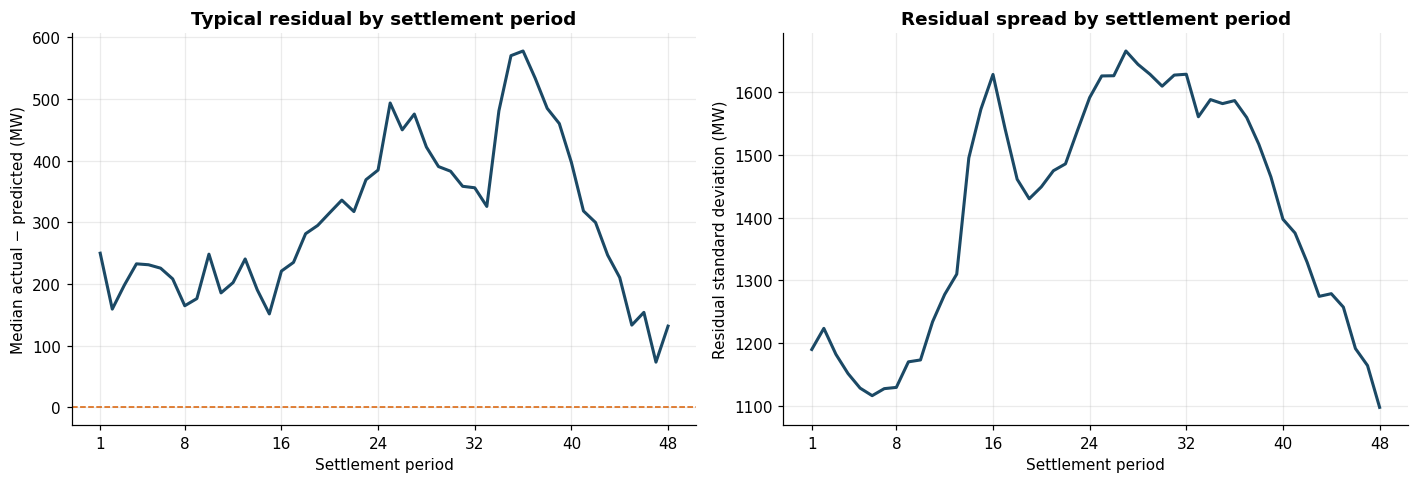

                   observations  median_residual_mw  residual_sd_mw
settlement_period                                                  
1                           890               250.0          1189.9
2                           890               159.4          1223.6
3                           890               198.2          1182.2
4                           890               232.7          1151.5
5                           890               231.3          1128.3
6                           890               225.7          1116.3
7                           890               208.3          1127.4
8                           890               164.8          1129.4
9                           890               176.4          1170.2
10                          890               248.4          1173.2
11                          890               185.6          1234.1
12                          890               202.4          1277.6
13                          890               24

In [3]:
period_diagnostics = (
    resid.groupby("settlement_period")["residual"]
    .agg(
        observations="size",
        median_residual_mw="median",
        residual_sd_mw="std"
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    period_diagnostics.index,
    period_diagnostics["median_residual_mw"],
    color=C["primary"],
    linewidth=2
)
axes[0].axhline(
    0, color=C["accent"], linestyle="--", linewidth=1
)
axes[0].set_ylabel("Median actual − predicted (MW)")
axes[0].set_title("Typical residual by settlement period")

axes[1].plot(
    period_diagnostics.index,
    period_diagnostics["residual_sd_mw"],
    color=C["primary"],
    linewidth=2
)
axes[1].set_ylabel("Residual standard deviation (MW)")
axes[1].set_title("Residual spread by settlement period")

for ax in axes:
    ax.set_xlabel("Settlement period")
    ax.set_xticks([1, 8, 16, 24, 32, 40, 48])

fig.tight_layout()
fig.savefig(FIG_DIR / "12_residual_structure.png")
plt.show()

print(period_diagnostics.round(1).to_string())

print(
    "\nPositive median residuals indicate typical underprediction, negative values indicate typical overprediction."
)
print(
    "Differences in spread help motivate period-specific scaling, but do not establish that a detection threshold is optimal."
)

### B3. Anomaly detection methods

**Robust z-score:** Checks whether a prediction error is unusually high or low for that half-hour of the day. It compares each residual with the typical value (median), allowing for how much residuals usually vary. Observations are flagged when the score is above 4 or below −4.

**Isolation Forest:** Looks for unusual combinations of demand, weather, calendar information and past demand. It is set to flag approx. 0.5% of the observations. A flagged observation may still have demand close to the model's prediction.

Both methods use the full historical analysis sample to identify unusual observations. Their scores describe how unusual an observation looks, not the probability that it is a genuine anomaly.

In [4]:
#Flagging robust scores beyond +/- and 5% of observations with Isolation Forest
THRESHOLD = 4.0
ISO_CONTAMINATION = 0.005

#Comparing residuals from the same hal-hour of the day
period_group = resid.groupby("settlement_period")["residual"]

#Finding the typical residual for each half-hour
period_median = period_group.transform("median")

#Measuring how far residuals fall from their median (Median absolute deviation = MAD)
period_mad = period_group.transform(
    lambda s: (s - s.median()).abs().median()
)

#Converting MAD to a scale comparable to standard deviation when residuals follow a normal distribution
robust_scale = 1.4826 * period_mad

#Checking if scale is finite and positive
invalid_scale = (~np.isfinite(robust_scale)) | (robust_scale <= 0)

assert not invalid_scale.any(), (
    "At least one settlement period has an invalid MAD scale."
)

#Measuring how far each residual is above or below its usual value, relative to the variation for that half-hour
resid["z_robust"] = (
    resid["residual"] - period_median
) / robust_scale

#1 for flagged and 0 for others
resid["anom_robust"] = (
    resid["z_robust"].abs() > THRESHOLD
).astype(int)

#Using weather, demand, time of day and past demand to identify unusual combinations of conditions
iso_features = [
    "tsd_mw",
    "temperature_c",
    "settlement_period",
    "day_of_week",
    "demand_lag_1d",
    "demand_roll_7d_avg",
    "heating_degrees"
]

#Checking for missing inputs
missing = sorted(set(iso_features) - set(resid.columns))
assert not missing, f"Missing Isolation Forest inputs: {missing}"

#Building 300 trees, fixing the random seed
iso = IsolationForest(
    n_estimators=300,
    contamination=ISO_CONTAMINATION,
    random_state=42,
    n_jobs=-1
)

#Fitting the detector
iso.fit(resid[iso_features])

#Reversing the original score --> larger values mean more unusual
resid["iso_score"] = -iso.score_samples(resid[iso_features])

#Iso Forest returns -1 for unusual obs', conerting to 1 for flagged and 0 for unflagged
resid["anom_iso"] = (
    iso.predict(resid[iso_features]) == -1
).astype(int)


#Counting the obs' flagged by each method
summary = pd.DataFrame({
    "method": [
        "Robust per-period z-score",
        "Isolation Forest"
    ],
    "flagged": [
        int(resid["anom_robust"].sum()),
        int(resid["anom_iso"].sum())
    ]
})

#Expressing as a percentage
summary["evaluated"] = len(resid)
summary["rate_%"] = (
    summary["flagged"] / summary["evaluated"] * 100
)

print("RETROSPECTIVE DETECTION SUMMARY")
print(summary.round(3).to_string(index=False))

print(f"\nRobust threshold: |z| > {THRESHOLD}")
print(f"Isolation Forest contamination: {ISO_CONTAMINATION:.1%}")
print("Scores from the two methods are not directly comparable.")

RETROSPECTIVE DETECTION SUMMARY
                   method  flagged  evaluated  rate_%
Robust per-period z-score      166      42700   0.389
         Isolation Forest      214      42700   0.501

Robust threshold: |z| > 4.0
Isolation Forest contamination: 0.5%
Scores from the two methods are not directly comparable.


### B4. Grouping consecutive flags

Consecutive half-hours flagged by the robust z-score method are grouped together. A group ends when an observation is missing, a half-hour is unflagged or a new day begins.
Each group's duration is the number of flagged half-hours multiplied by 30 minutes. Grouping makes longer periods of unusual demand easier to examine, but does not mean the flags share the same cause.

The largest difference between actual and predicted demand is reported for each group. Its direction shows whether demand at that point was above or below the prediction. Other observations in the group may differ.

In [5]:
#Grouping consecutive flagged half-hours
def to_events(frame, flag_col):
    columns = [
        "start_date", "start_period", "end_period",
        "n_periods", "duration_hours",
        "peak_residual_mw", "peak_actual_mw",
        "peak_expected_mw", "direction",
        "is_bank_holiday", "month"
    ]

    #Keeping flagged obs', arranging them in date and time order
    flagged = (
        frame.loc[frame[flag_col] == 1]
        .sort_values(["settlement_date", "settlement_period"])
        .copy()
    )

    if flagged.empty:
        return pd.DataFrame(columns=columns)

    #Satrting a new group when the day changes or period numbers skip (skip=half-hour is missing or unflagged)
    new_run = (
        flagged["settlement_date"].ne(
            flagged["settlement_date"].shift()
        )
        | flagged["settlement_period"].diff().ne(1)
    )

    #Giving each group its own number
    flagged["run_id"] = new_run.cumsum()
    rows = []

    for _, block in flagged.groupby("run_id"):
        #Finding the largest difference between actual and predicted demand (regardless of demand was above or below prediction)
        peak = block.loc[block["residual"].abs().idxmax()]

        #Recording the group's timing, duration, largest deviation
        #Each flagged half-hours contribute 0.5 hours to the duration
        rows.append({
            "start_date": block["settlement_date"].iloc[0],
            "start_period": int(block["settlement_period"].iloc[0]),
            "end_period": int(block["settlement_period"].iloc[-1]),
            "n_periods": len(block),
            "duration_hours": len(block) * 0.5,
            "peak_residual_mw": float(peak["residual"]),
            "peak_actual_mw": float(peak[TARGET]),
            "peak_expected_mw": float(peak["predicted"]),
            #Direction to describe the largest deviation int he group
            "direction": (
                "above_expected" if peak["residual"] > 0
                else "below_expected" if peak["residual"] < 0
                else "equal_to_expected"
            ),
            "is_bank_holiday": int(peak["is_bank_holiday"]),
            "month": int(peak["month"])
        })

    #Listing groups with largest deviation first
    return (
        pd.DataFrame(rows, columns=columns)
        .sort_values(
            "peak_residual_mw",
            key=lambda s: s.abs(),
            ascending=False
        )
        .reset_index(drop=True)
    )

#Applying the grouping to obs' flagged by robust z-score
events_robust = to_events(resid, "anom_robust")

#Checking if grouped half-hours=original flag count
assert (
    events_robust["n_periods"].sum()
    == resid["anom_robust"].sum()
)

#Summarising group durations, displaying the 15 largest deviations
print(f"Flagged half-hours: {int(resid['anom_robust'].sum()):,}")
print(f"Consecutive runs: {len(events_robust):,}")

if not events_robust.empty:
    print(
        f"Mean run duration: "
        f"{events_robust['duration_hours'].mean():.1f} hours"
    )
    print(
        f"Longest run: "
        f"{events_robust['duration_hours'].max():.1f} hours"
    )

    print("\nTop 15 runs by absolute peak residual:")
    print(events_robust.head(15).round(1).to_string(index=False))
else:
    print("No runs detected at the current threshold.")

Flagged half-hours: 166
Consecutive runs: 52
Mean run duration: 1.6 hours
Longest run: 6.5 hours

Top 15 runs by absolute peak residual:
start_date  start_period  end_period  n_periods  duration_hours  peak_residual_mw  peak_actual_mw  peak_expected_mw      direction  is_bank_holiday  month
2024-01-08            14          25         12             6.0            9280.0         39715.0           30435.0 above_expected                0      1
2024-01-09             9          21         13             6.5            7977.6         41818.0           33840.4 above_expected                0      1
2023-12-03            21          30         10             5.0            7720.2         40868.0           33147.8 above_expected                0     12
2023-12-25            34          43         10             5.0           -7377.5         26116.0           33493.5 below_expected                1     12
2024-01-08            31          33          3             1.5            7034.6       

### B5. Do the methods agree?

Comparing observations flagged by both methods with those flagged by only one. Observations flagged by both are labelled as consensus flags.

The methods look for different types of unusual behaviour -->  some disagreement is expected. Agreement does not confirm a genuine anomaly.

#### Comparing the methods

In [6]:
#Obs' flagged by each method
robust_flag = resid["anom_robust"].eq(1)
iso_flag = resid["anom_iso"].eq(1)

#Finding both flagged or flagged by one method
both = robust_flag & iso_flag
either = robust_flag | iso_flag

#Storing 1 when both, 0 otherwise
resid["anom_consensus"] = both.astype(int)

#Counting half-hours in 4 categories
overlap_summary = pd.DataFrame({
    "Category": [
        "Neither method",
        "Robust z-score only",
        "Isolation Forest only",
        "Both methods (consensus)",
    ],
    "Half-hours": [
        (~either).sum(),
        (robust_flag & ~iso_flag).sum(),
        (iso_flag & ~robust_flag).sum(),
        both.sum(),
    ],
})

#Expressing each category as % of all evaluated half-hours
overlap_summary["Share of evaluated (%)"] = (
    overlap_summary["Half-hours"] / len(resid) * 100
)

print(overlap_summary.round(3).to_string(index=False))

intersection_count = int(both.sum())
union_count = int(either.sum())

print(f"\nFlagged by at least one method: {union_count:,}")
print(f"Flagged by both methods: {intersection_count:,}")


#Jaccard overlap =share of all flagged obs' that both methods identified
#Measuring agreement not accuracy
if union_count:
    jaccard = intersection_count / union_count
    print(f"Jaccard overlap: {jaccard:.1%}")
else:
    print("Jaccard overlap: undefined - neither method flagged observations.")

                Category  Half-hours  Share of evaluated (%)
          Neither method       42344                  99.166
     Robust z-score only         142                   0.333
   Isolation Forest only         190                   0.445
Both methods (consensus)          24                   0.056

Flagged by at least one method: 356
Flagged by both methods: 24
Jaccard overlap: 6.7%


#### Examining the group with the largest deviation

Observations found for 08 Jan 2024: 48


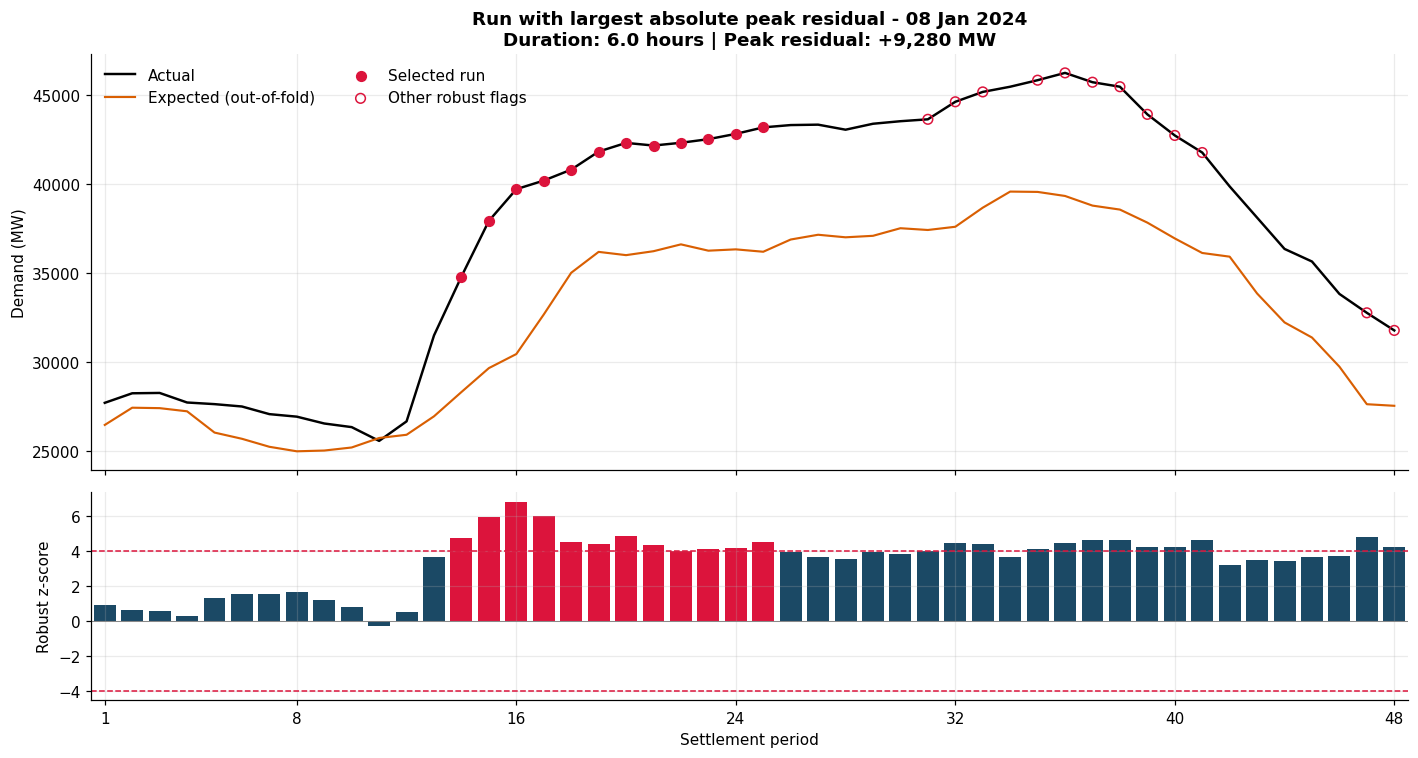

In [7]:
#If the robust method produced flagged groups
if events_robust.empty:
    print("No robust z-score runs to plot.")

else:
    top = events_robust.iloc[0]
    event_date = pd.Timestamp(top["start_date"]).normalize()

    #Selecting all obs' from that day with consistent date format
    dates = pd.to_datetime(resid["settlement_date"]).dt.normalize()
    day_rows = resid.loc[dates.eq(event_date)].copy()

    #Converting settlement periods to whole numbers
    day_rows["settlement_period"] = pd.to_numeric(
        day_rows["settlement_period"], errors="raise"
    ).astype(int)

    print(f"Observations found for {event_date:%d %b %Y}: {len(day_rows)}")

    if day_rows.empty:
        raise ValueError("No observations matched the selected event date.")

    #Arranging the day into periods 1-48 (missing periods remain empty)
    day = (
        day_rows
        .set_index("settlement_period")
        .sort_index()
        .reindex(range(1, 49))
    )

    if day[[TARGET, "predicted", "z_robust"]].isna().all().any():
        raise ValueError("A required plotting column contains no valid values.")

    #Identifying flags belonging to the selected group
    selected_run = (
        (day.index >= int(top["start_period"]))
        & (day.index <= int(top["end_period"]))
        & day["anom_robust"].eq(1)
    )

    #Keeping other flags from the same day separate
    other_flags = day["anom_robust"].eq(1) & ~selected_run

    fig, axes = plt.subplots(
        2, 1,
        figsize=(13, 7),
        sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )

    #Comparing actual demand with the model's prediction through the day
    axes[0].plot(
        day.index, day[TARGET],
        color="black", linewidth=1.6,
        label="Actual"
    )
    axes[0].plot(
        day.index, day["predicted"],
        color=C["accent"], linewidth=1.4,
        label="Expected (out-of-fold)"
    )

    axes[0].scatter(
        day.index[selected_run],
        day.loc[selected_run, TARGET],
        color="crimson", s=40, zorder=5,
        label="Selected run"
    )

    if other_flags.any():
        axes[0].scatter(
            day.index[other_flags],
            day.loc[other_flags, TARGET],
            facecolors="none", edgecolors="crimson",
            s=40, zorder=5,
            label="Other robust flags"
        )

    axes[0].set_ylabel("Demand (MW)")
    axes[0].set_title(
        f"Run with largest absolute peak residual - "
        f"{event_date:%d %b %Y}\n"
        f"Duration: {top['duration_hours']:.1f} hours | "
        f"Peak residual: {top['peak_residual_mw']:+,.0f} MW"
    )
    axes[0].legend(frameon=False, ncol=2)

    bar_colours = np.where(
        selected_run, "crimson", C["primary"]
    )
    axes[1].bar(
        day.index, day["z_robust"],
        color=bar_colours, width=0.8
    )

    for threshold in (-THRESHOLD, THRESHOLD):
        axes[1].axhline(
            threshold, color="crimson",
            linestyle="--", linewidth=1
        )

    axes[1].axhline(0, color="grey", linewidth=0.6)
    axes[1].set_ylabel("Robust z-score")
    axes[1].set_xlabel("Settlement period")
    axes[1].set_xticks([1, 8, 16, 24, 32, 40, 48])
    axes[1].set_xlim(0.5, 48.5)

    fig.tight_layout()
    fig.savefig(
        FIG_DIR / "13_largest_anomaly.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()

#### Comparing flag rates across time

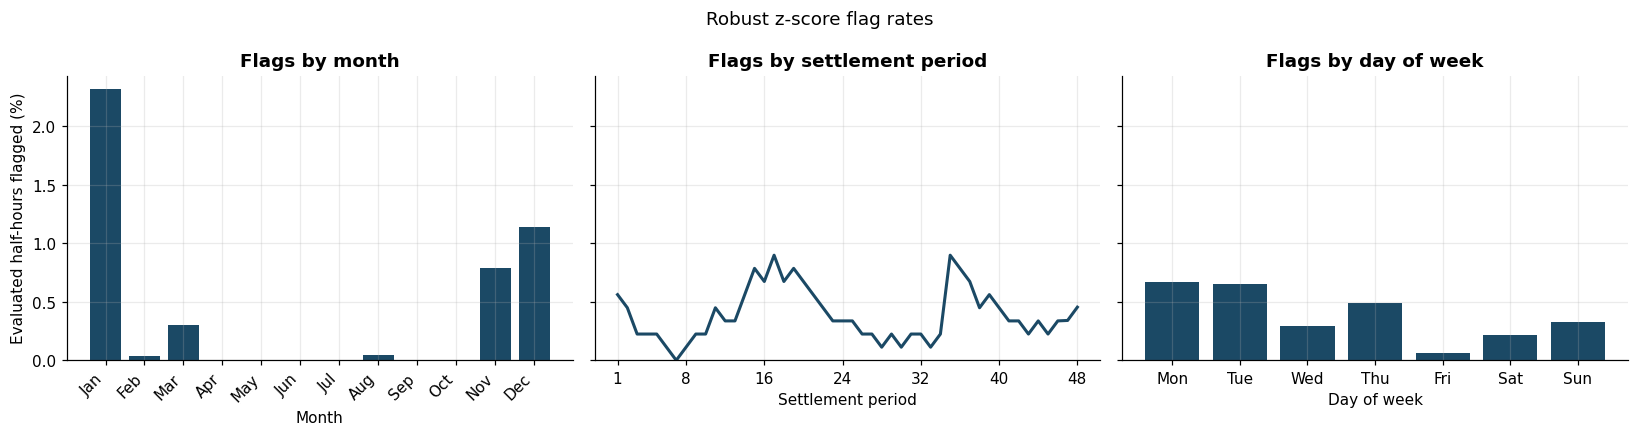

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

#Examinin g flags by month, half-hour of the day, day of the week
plot_specs = [
    ("month", range(1, 13), "Month"),
    ("settlement_period", range(1, 49), "Settlement period"),
    ("day_of_week", range(7), "Day of week"),
]

for ax, (column, categories, label) in zip(axes, plot_specs):
    #Counting flagged and evaluated half-hours whitin each category
    summary = (
        resid.groupby(column)["anom_robust"]
        .agg(flagged="sum", evaluated="size")
        .reindex(categories)
    )

    # % for different numbers of obs' across categories
    rate = 100 * summary["flagged"] / summary["evaluated"]

    #Line to show how flag rates change through the day
    if column == "settlement_period":
        ax.plot(
            rate.index, rate.values,
            color=C["primary"], linewidth=2
        )
        ax.set_xticks([1, 8, 16, 24, 32, 40, 48])

    else:
        ax.bar(rate.index, rate.values, color=C["primary"])

        if column == "month":
            ax.set_xticks(range(1, 13))
            ax.set_xticklabels(
                ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
                rotation=45, ha="right"
            )
        else:
            ax.set_xticks(range(7))
            ax.set_xticklabels(
                ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
            )

    ax.set_title(f"Flags by {label.lower()}")
    ax.set_xlabel(label)
    ax.set_ylim(bottom=0)

axes[0].set_ylabel("Evaluated half-hours flagged (%)")
fig.suptitle("Robust z-score flag rates")
fig.tight_layout()

fig.savefig(
    FIG_DIR / "14_anomaly_distribution.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

### B6. Writing results to the database

In [9]:
export_dates = (
    pd.to_datetime(resid["settlement_date"])
    .dt.strftime("%Y-%m-%d")
)

OOF_MODEL_NAME = f"{type(model_template).__name__} (out-of-fold)"

conn.execute("""
    CREATE TABLE IF NOT EXISTS anomalies (
        settlement_date TEXT NOT NULL,
        settlement_period INTEGER NOT NULL,
        method TEXT NOT NULL,
        actual_demand_mw REAL,
        expected_demand_mw REAL,
        residual_mw REAL,
        anomaly_score REAL,
        is_anomaly INTEGER CHECK (is_anomaly IN (0,1)),
        created_at TEXT DEFAULT (datetime('now')),
        PRIMARY KEY (settlement_date, settlement_period, method));
""")

to_write=[]
for method, flag, sc in [("robust_zscore","anom_robust","z_robust"),
                         ("isolation_forest","anom_iso","iso_score"),
                         ("consensus","anom_consensus","z_robust")]:
    s = resid[resid[flag] == 1]
    to_write.append(pd.DataFrame({
        "settlement_date": export_dates.loc[s.index].values,
        "settlement_period": s["settlement_period"].values, "method": method,
        "actual_demand_mw": s["tsd_mw"].values,
        "expected_demand_mw": s["predicted"].values,
        "residual_mw": s["residual"].values,
        "anomaly_score": s[sc].abs().values, "is_anomaly": 1}))
anom_df = pd.concat(to_write, ignore_index=True)
conn.execute("DELETE FROM anomalies;")
anom_df.to_sql("anomalies", conn, if_exists="append", index=False)

oof_df = pd.DataFrame({
    "settlement_date": export_dates.values,
    "settlement_period": resid["settlement_period"].astype(int).values,
    "model_name": OOF_MODEL_NAME,
    "predicted_demand_mw": resid["predicted"].values,
    "data_split": "validation",
})

conn.execute("DELETE FROM model_predictions WHERE data_split = 'validation';")
oof_df.to_sql("model_predictions", conn, if_exists="append", index=False)
conn.commit()
print(f"anomalies         : {conn.execute('SELECT COUNT(*) FROM anomalies').fetchone()[0]:,} rows")
print(f"model_predictions : {conn.execute('SELECT COUNT(*) FROM model_predictions').fetchone()[0]:,} rows")


events_robust.to_csv(
    PROCESSED_DIR / "anomaly_events.csv",
    index=False
)
print(f"Saved anomaly_events.csv: {len(events_robust):,} runs")

print("\nFlagged rows saved by method:")
print(anom_df.groupby("method").size().to_string())

print(f"\nOut-of-fold predictions saved: {len(oof_df):,}")
print(f"Prediction model: {OOF_MODEL_NAME}")

conn.close()
print("Connection closed.")


anomalies         : 404 rows
model_predictions : 200,290 rows
Saved anomaly_events.csv: 52 runs

Flagged rows saved by method:
method
consensus            24
isolation_forest    214
robust_zscore       166

Out-of-fold predictions saved: 42,700
Prediction model: LGBMRegressor (out-of-fold)
Connection closed.
